# Profit & Margin Analysis

# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Understanding

## Import Dataset dan Sumber, Nama, Format, serta Tujuan Dataset

### Import Data

In [2]:
order_items = pd.DataFrame(pd.read_csv("order_items.csv")) # Membaca file csv dan mengubahnya dalam bentuk DataFrame (Tabel)
inventory = pd.DataFrame(pd.read_csv("inventory_items.csv"))

In [3]:
'''Menggabungkan Tabel dengan Outer Join'''
df = order_items.merge(
    inventory.drop(columns=["product_id"]),
    left_on="inventory_item_id", right_on="id",
    how="left", suffixes=("_order_item", "_inventory")
)

In [4]:
pd.set_option("display.max_columns", None)
df

,id_order_item,order_id,user_id,product_id,inventory_item_id,status,created_at_order_item,shipped_at,delivered_at,returned_at,sale_price,id_inventory,created_at_inventory,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,152013,104663,83582,14235,410368,Cancelled,2023-05-07 06:08:40+00:00,NaN,NaN,NaN,0.02,410368,2021-09-09 06:17:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1
1,40993,28204,22551,14235,110590,Complete,2023-03-14 03:47:21+00:00,2023-03-15 22:57:00+00:00,2023-03-18 01:08:00+00:00,NaN,0.02,110590,2023-06-05 15:24:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1
2,51224,35223,28215,14235,138236,Complete,2023-12-05 13:25:30+00:00,2023-12-06 01:20:00+00:00,2023-12-10 10:04:00+00:00,NaN,0.02,138236,2020-04-12 14:36:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1
3,36717,25278,20165,14235,99072,Shipped,2023-12-22 20:48:19+00:00,2023-12-24 16:44:00+00:00,NaN,NaN,0.02,99072,2020-01-24 05:47:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1
4,131061,90241,71954,14235,353798,Shipped,2022-06-19 16:57:59+00:00,2022-06-19 19:29:00+00:00,NaN,NaN,0.02,353798,2022-09-13 16:58:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
181754,9674,6679,5325,24447,26095,Returned,2020-12-23 00:05:01+00:00,2020-12-25 22:54:00+00:00,2020-12-28 07:08:00+00:00,2020-12-30 22:43:00+00:00,999.00,26095,2021-10-07 09:37:00+00:00,NaN,404.595001,Outerwear & Coats,Darla,Alpha Industries,999.00,Men,1CE5E897CDA6AEB211DFFE8D514F4365,5
181755,7801,5416,4283,24447,21078,Shipped,2022-01-12 23:51:07+00:00,2022-01-10 03:42:00+00:00,NaN,NaN,999.00,21078,2023-09-16 00:38:00+00:00,NaN,404.595001,Outerwear & Coats,Darla,Alpha Industries,999.00,Men,1CE5E897CDA6AEB211DFFE8D514F4365,5
181756,62986,43364,34691,23546,169937,Shipped,2023-02-26 00:38:43+00:00,2023-02-25 06:53:00+00:00,NaN,NaN,999.00,169937,2021-11-03 11:45:00+00:00,NaN,482.516999,Shorts,Alpha Industries Rip Stop Short,Alpha Industries,999.00,Men,C1AA157F9E8516370E3345F226EF62FC,5
181757,106577,73418,58623,24447,287560,Shipped,2023-11-12 02:41:02+00:00,2023-11-14 20:44:00+00:00,NaN,NaN,999.00,287560,2022-11-04 09:27:00+00:00,NaN,404.595001,Outerwear & Coats,Darla,Alpha Industries,999.00,Men,1CE5E897CDA6AEB211DFFE8D514F4365,5


### Sumber, Nama, Format, serta Tujuan Dataset

### Baris, Kolom, dan Tipe Data

In [5]:
df.info() # Untuk mengetahui jumlah baris dan kolom, nama nama kolom, dan tipe data tiap kolom

<class 'pandas.DataFrame'>
RangeIndex: 181759 entries, 0 to 181758
Data columns (total 22 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id_order_item                   181759 non-null  int64  
 1   order_id                        181759 non-null  int64  
 2   user_id                         181759 non-null  int64  
 3   product_id                      181759 non-null  int64  
 4   inventory_item_id               181759 non-null  int64  
 5   status                          181759 non-null  str    
 6   created_at_order_item           181759 non-null  str    
 7   shipped_at                      118281 non-null  str    
 8   delivered_at                    63841 non-null   str    
 9   returned_at                     18232 non-null   str    
 10  sale_price                      181759 non-null  float64
 11  id_inventory                    181759 non-null  int64  
 12  created_at_inventory       

### Deskripsi Kolom

### Deskriptif Statistik dengan .describe()

In [6]:
df.describe() # Untuk mengetahui informasi statistik deskriptif pada kolom dengan tipe data integer dan float

,id_order_item,order_id,user_id,product_id,inventory_item_id,sale_price,id_inventory,cost,product_retail_price,product_distribution_center_id
count,181759.000000,181759.000000,181759.000000,181759.000000,181759.000000,181759.000000,181759.000000,181759.000000,181759.000000,181759.000000
mean,90880.000000,62579.982609,49983.272020,15254.151838,245291.860007,59.568544,245291.860007,28.655281,59.568544,5.008748
std,52469.448126,36125.987285,28830.895739,8413.482833,141661.912894,66.657262,141661.912894,31.022340,66.657262,2.900402
min,1.000000,1.000000,1.000000,1.000000,3.000000,0.020000,3.000000,0.008300,0.020000,1.000000
25%,45440.500000,31266.500000,25031.500000,7979.500000,122565.000000,24.500000,122565.000000,11.366210,24.500000,2.000000
50%,90880.000000,62529.000000,49983.000000,15966.000000,245284.000000,39.990002,245284.000000,19.829000,39.990002,5.000000
75%,136319.500000,93845.500000,74867.500000,22504.000000,367983.000000,69.949997,367983.000000,34.545320,69.949997,8.000000
max,181759.000000,125226.000000,100000.000000,29120.000000,490705.000000,999.000000,490705.000000,557.151002,999.000000,10.000000


## Data Exploration

### Membuat Copy Dataset

In [7]:
df_copy = df.copy() # Membuat copy dataset

### Inkonsistensi Data

In [8]:
inkonsistensi = df_copy.select_dtypes(include=["str"]).columns # Mengambil nama kolom dengan tipe data string

In [9]:
for i in inkonsistensi : # Memeriksa inkonsistensi data pada kolom dengan tipe data string
    print(f"Kolom {i} :")
    print(df_copy[i].unique())
    print("\n")

Kolom status :
<ArrowStringArray>
['Cancelled', 'Complete', 'Shipped', 'Processing', 'Returned']
Length: 5, dtype: str


Kolom created_at_order_item :
<ArrowStringArray>
['2023-05-07 06:08:40+00:00', '2023-03-14 03:47:21+00:00',
 '2023-12-05 13:25:30+00:00', '2023-12-22 20:48:19+00:00',
 '2022-06-19 16:57:59+00:00', '2023-09-19 09:13:08+00:00',
 '2021-10-31 01:26:46+00:00', '2022-04-01 13:25:52+00:00',
 '2023-10-29 08:08:40+00:00', '2024-01-07 23:06:39+00:00',
 ...
 '2023-06-15 11:58:18+00:00', '2023-10-16 06:50:15+00:00',
 '2023-06-17 15:30:18+00:00', '2023-01-28 15:06:39+00:00',
 '2023-10-24 18:42:24+00:00', '2020-12-23 00:05:01+00:00',
 '2022-01-12 23:51:07+00:00', '2023-02-26 00:38:43+00:00',
 '2023-11-12 02:41:02+00:00', '2022-03-13 10:29:49+00:00']
Length: 181526, dtype: str


Kolom shipped_at :
<ArrowStringArray>
[                               nan,        '2023-03-15 22:57:00+00:00',
        '2023-12-06 01:20:00+00:00',        '2023-12-24 16:44:00+00:00',
        '2022-06-19 19

In [10]:
'''Extract dalam bentuk excel'''
pd.DataFrame(df_copy["product_name"].unique()).to_excel("product_name_unique.xlsx", index=False)
pd.DataFrame(df_copy["product_brand"].unique()).to_excel("product_brand_unique.xlsx", index=False)

### Missing Value (Jumlah dan Persentase)

In [11]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value

In [12]:
df_missing_summary = pd.DataFrame({
    "Jumlah Missing Value": df_copy_miss,
    "Persentase (%)": df_copy_miss_percentage
})
df_missing_summary = df_missing_summary.sort_values(by=("Jumlah Missing Value"), ascending=False)
display(df_missing_summary)

,Jumlah Missing Value,Persentase (%)
sold_at,181759,100.000000
returned_at,163527,89.969135
delivered_at,117918,64.876017
shipped_at,63478,34.924268
product_brand,149,0.081977
product_name,10,0.005502
status,0,0.000000
inventory_item_id,0,0.000000
product_id,0,0.000000
user_id,0,0.000000


In [13]:
df_copy[df_copy["sold_at"].notnull()]["status"].unique()

<ArrowStringArray>
[]
Length: 0, dtype: str

In [14]:
df_copy[df_copy["sold_at"].isnull()]["status"].unique()

<ArrowStringArray>
['Cancelled', 'Complete', 'Shipped', 'Processing', 'Returned']
Length: 5, dtype: str

In [15]:
df_copy[df_copy["returned_at"].notnull()]["status"].unique()

<ArrowStringArray>
['Returned']
Length: 1, dtype: str

In [16]:
df_copy[df_copy["returned_at"].isnull()]["status"].unique()

<ArrowStringArray>
['Cancelled', 'Complete', 'Shipped', 'Processing']
Length: 4, dtype: str

In [17]:
df_copy[df_copy["delivered_at"].notnull()]["status"].unique()

<ArrowStringArray>
['Complete', 'Returned']
Length: 2, dtype: str

In [18]:
df_copy[df_copy["delivered_at"].isnull()]["status"].unique()

<ArrowStringArray>
['Cancelled', 'Shipped', 'Processing']
Length: 3, dtype: str

In [19]:
df_copy[(df_copy["shipped_at"].notnull())]["status"].unique()

<ArrowStringArray>
['Complete', 'Shipped', 'Returned']
Length: 3, dtype: str

In [20]:
df_copy[df_copy["shipped_at"].isnull()]["status"].unique()

<ArrowStringArray>
['Cancelled', 'Processing']
Length: 2, dtype: str

### Duplicate Value (Jumlah dan Persentase)

In [21]:
duplicate_all = df_copy.duplicated().sum() # Memeriksa jumlah duplicate value berdasarkan tiap baris
persent_duplicate_all = duplicate_all /len(df_copy)*100 # Menghitung persentase duplicate value
df_duplicate_summary = pd.DataFrame({
    "Metrik": ["Jumlah Baris Duplikat", "Persentase Duplikat"],
    "Nilai": [duplicate_all, f"{persent_duplicate_all:.2f}%"]
})
display(df_duplicate_summary)

,Metrik,Nilai
0,Jumlah Baris Duplikat,0
1,Persentase Duplikat,0.00%


### Encoder Kolom Kategori Untuk Periksa Outlier

In [22]:
from sklearn.preprocessing import LabelEncoder # Memanggil Library untuk LabelEncoder

In [23]:
le = LabelEncoder()

In [24]:
for col in df_copy.select_dtypes(include=["object", "category", "str"]).columns:
    # Membuat kolom baru dengan tambahan "_encoded"
    df_copy[col + "_encoded"] = le.fit_transform(df_copy[col].astype(str))

df_copy

,id_order_item,order_id,user_id,product_id,inventory_item_id,status,created_at_order_item,shipped_at,delivered_at,returned_at,sale_price,id_inventory,created_at_inventory,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id,status_encoded,created_at_order_item_encoded,shipped_at_encoded,delivered_at_encoded,returned_at_encoded,created_at_inventory_encoded,sold_at_encoded,product_category_encoded,product_name_encoded,product_brand_encoded,product_department_encoded,product_sku_encoded
0,152013,104663,83582,14235,410368,Cancelled,2023-05-07 06:08:40+00:00,NaN,NaN,NaN,0.02,410368,2021-09-09 06:17:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1,0,104257,79123,43187,12478,71989,0,0,12562,2736,1,15001
1,40993,28204,22551,14235,110590,Complete,2023-03-14 03:47:21+00:00,2023-03-15 22:57:00+00:00,2023-03-18 01:08:00+00:00,NaN,0.02,110590,2023-06-05 15:24:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1,1,94454,41844,22590,12478,145915,0,0,12562,2736,1,15001
2,51224,35223,28215,14235,138236,Complete,2023-12-05 13:25:30+00:00,2023-12-06 01:20:00+00:00,2023-12-10 10:04:00+00:00,NaN,0.02,138236,2020-04-12 14:36:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1,1,157634,68917,37758,12478,11815,0,0,12562,2736,1,15001
3,36717,25278,20165,14235,99072,Shipped,2023-12-22 20:48:19+00:00,2023-12-24 16:44:00+00:00,NaN,NaN,0.02,99072,2020-01-24 05:47:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1,4,164116,71879,43187,12478,2673,0,0,12562,2736,1,15001
4,131061,90241,71954,14235,353798,Shipped,2022-06-19 16:57:59+00:00,2022-06-19 19:29:00+00:00,NaN,NaN,0.02,353798,2022-09-13 16:58:00+00:00,NaN,0.008300,Accessories,Indestructable Aluminum Aluma Wallet - RED,marshal,0.02,Women,8425BC94A44E3D1BB3C8C026B2702C00,1,4,57286,25301,43187,12478,114993,0,0,12562,2736,1,15001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
181754,9674,6679,5325,24447,26095,Returned,2020-12-23 00:05:01+00:00,2020-12-25 22:54:00+00:00,2020-12-28 07:08:00+00:00,2020-12-30 22:43:00+00:00,999.00,26095,2021-10-07 09:37:00+00:00,NaN,404.595001,Outerwear & Coats,Darla,Alpha Industries,999.00,Men,1CE5E897CDA6AEB211DFFE8D514F4365,5,3,15845,7102,3827,1091,75240,0,11,7513,99,0,3316
181755,7801,5416,4283,24447,21078,Shipped,2022-01-12 23:51:07+00:00,2022-01-10 03:42:00+00:00,NaN,NaN,999.00,21078,2023-09-16 00:38:00+00:00,NaN,404.595001,Outerwear & Coats,Darla,Alpha Industries,999.00,Men,1CE5E897CDA6AEB211DFFE8D514F4365,5,4,41719,18324,43187,12478,157953,0,11,7513,99,0,3316
181756,62986,43364,34691,23546,169937,Shipped,2023-02-26 00:38:43+00:00,2023-02-25 06:53:00+00:00,NaN,NaN,999.00,169937,2021-11-03 11:45:00+00:00,NaN,482.516999,Shorts,Alpha Industries Rip Stop Short,Alpha Industries,999.00,Men,C1AA157F9E8516370E3345F226EF62FC,5,4,91633,40451,43187,12478,78420,0,15,2243,99,0,21986
181757,106577,73418,58623,24447,287560,Shipped,2023-11-12 02:41:02+00:00,2023-11-14 20:44:00+00:00,NaN,NaN,999.00,287560,2022-11-04 09:27:00+00:00,NaN,404.595001,Outerwear & Coats,Darla,Alpha Industries,999.00,Men,1CE5E897CDA6AEB211DFFE8D514F4365,5,4,149530,65784,43187,12478,120843,0,11,7513,99,0,3316


### Outlier (Jumlah dan Persentase Dengan IQR)

In [25]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_numerik = df_copy.select_dtypes(include=["float64", "int64"]).columns

In [26]:
kolom_numerik

Index(['id_order_item', 'order_id', 'user_id', 'product_id',
       'inventory_item_id', 'sale_price', 'id_inventory', 'cost',
       'product_retail_price', 'product_distribution_center_id',
       'status_encoded', 'created_at_order_item_encoded', 'shipped_at_encoded',
       'delivered_at_encoded', 'returned_at_encoded',
       'created_at_inventory_encoded', 'sold_at_encoded',
       'product_category_encoded', 'product_name_encoded',
       'product_brand_encoded', 'product_department_encoded',
       'product_sku_encoded'],
      dtype='str')

In [27]:
summary_data = []
kolom_dengan_outlier = []

for i in kolom_numerik:
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum()
    persentase_outlier = (jumlah_outlier / len(outlier)) * 100
    
    # Simpan data ke dalam list untuk dibuat DataFrame nanti
    summary_data.append({
        "Kolom": i,
        "Jumlah Outlier": jumlah_outlier,
        "Persentase (%)": persentase_outlier
    })
    
    # Cek apakah kolom ini memiliki outlier (> 0)
    if jumlah_outlier > 0:
        kolom_dengan_outlier.append(df_copy[i])

df_outlier_summary = pd.DataFrame(summary_data).sort_values(by=("Jumlah Outlier"), ascending=False)

display(df_outlier_summary) 

,Kolom,Jumlah Outlier,Persentase (%)
14,returned_at_encoded,18232,10.030865
13,delivered_at_encoded,18137,9.978598
5,sale_price,15444,8.496966
8,product_retail_price,15444,8.496966
7,cost,13717,7.546806
0,id_order_item,0,0.000000
4,inventory_item_id,0,0.000000
3,product_id,0,0.000000
2,user_id,0,0.000000
1,order_id,0,0.000000


### Outlier dengan Boxplot

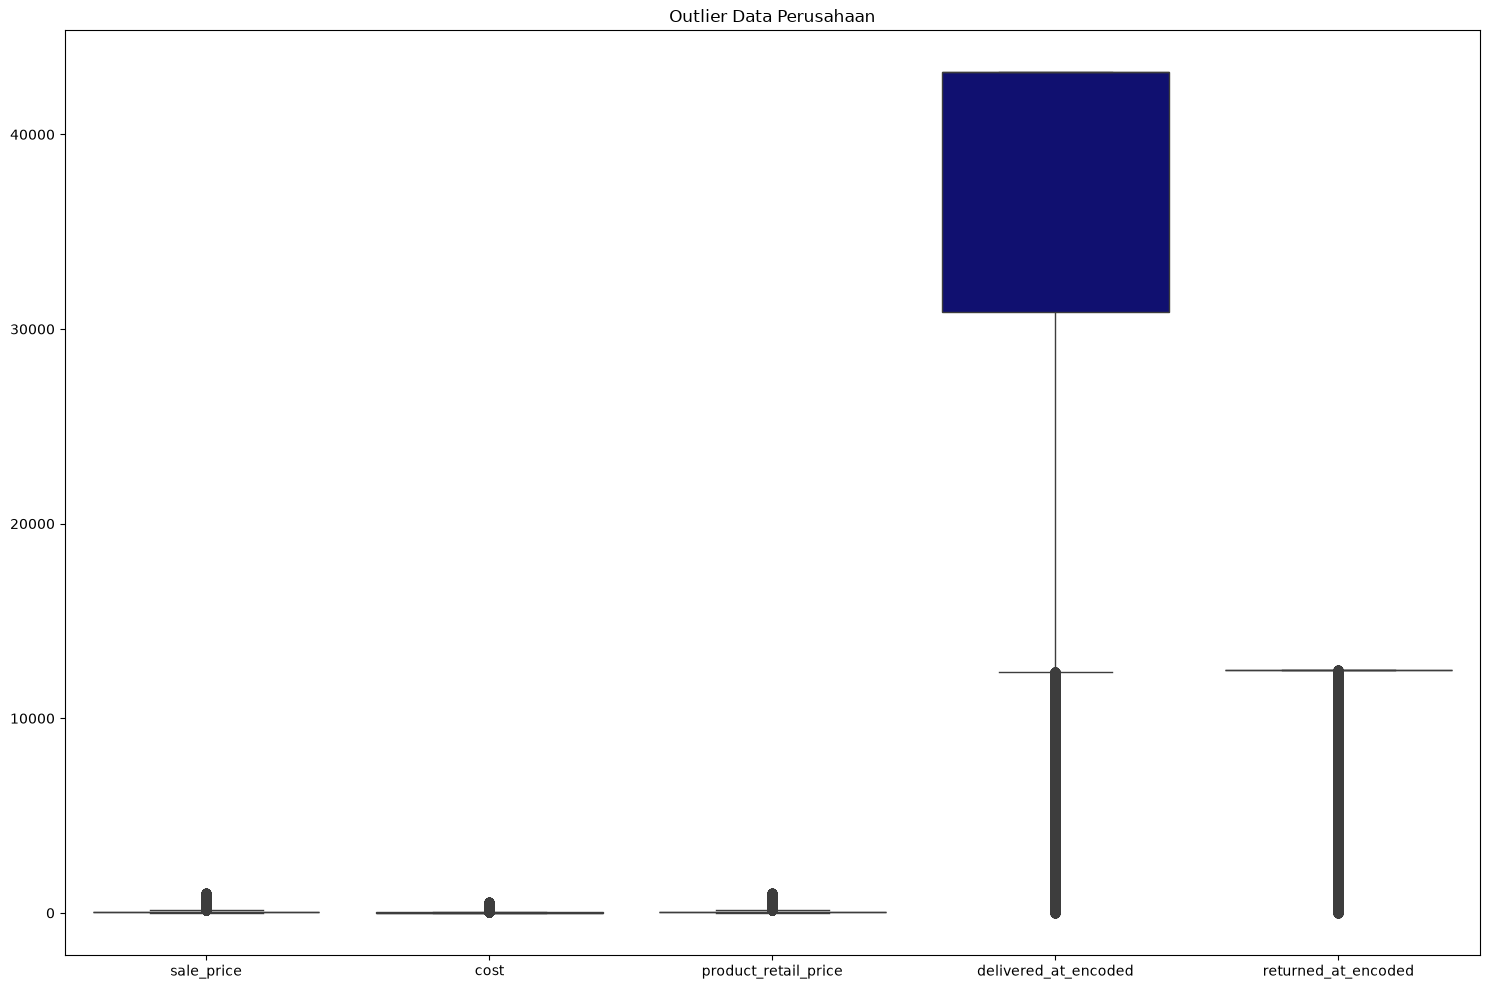

In [28]:
plt.figure(figsize=(15,10))
sns.boxplot(kolom_dengan_outlier, color="navy")
plt.title("Outlier Data Perusahaan")
plt.tight_layout()
plt.show()

### Distribusi Data (Dengan Uji D'Agostino-Pearson)

In [29]:
from scipy.stats import normaltest

In [30]:
summary_normal = []
alpha = 0.05
for i in kolom_numerik :
    statistic, p_value = normaltest(df_copy[i])

    if p_value < alpha:
        kesimpulan = "Tidak Normal (Tolak H0)"
    else:
        kesimpulan = "Normal (Gagal Tolak H0)"

    summary_normal.append({
        "Kolom": i,
        "Statistic": statistic,
        "p-value": p_value,
        "Kesimpulan": kesimpulan
    })

df_normal_summary = pd.DataFrame(summary_normal)
df_normal_summary = df_normal_summary.sort_values(by=("p-value"), ascending=False)
display(df_normal_summary)

,Kolom,Statistic,p-value,Kesimpulan
0,id_order_item,1.612969e+05,0.0,Tidak Normal (Tolak H0)
1,order_id,1.617605e+05,0.0,Tidak Normal (Tolak H0)
2,user_id,1.564234e+05,0.0,Tidak Normal (Tolak H0)
3,product_id,1.467804e+05,0.0,Tidak Normal (Tolak H0)
4,inventory_item_id,1.614699e+05,0.0,Tidak Normal (Tolak H0)
5,sale_price,1.846943e+05,0.0,Tidak Normal (Tolak H0)
6,id_inventory,1.614699e+05,0.0,Tidak Normal (Tolak H0)
7,cost,1.844055e+05,0.0,Tidak Normal (Tolak H0)
8,product_retail_price,1.846943e+05,0.0,Tidak Normal (Tolak H0)
9,product_distribution_center_id,5.077039e+05,0.0,Tidak Normal (Tolak H0)


### Distribusi Data (Dengan Histogram)

In [31]:
'''Membuat Variabel Baru Untuk Mengambil Kolom Dengan Tipe Data Numerikal'''
numeric_df = df_copy.select_dtypes(include=["number"])

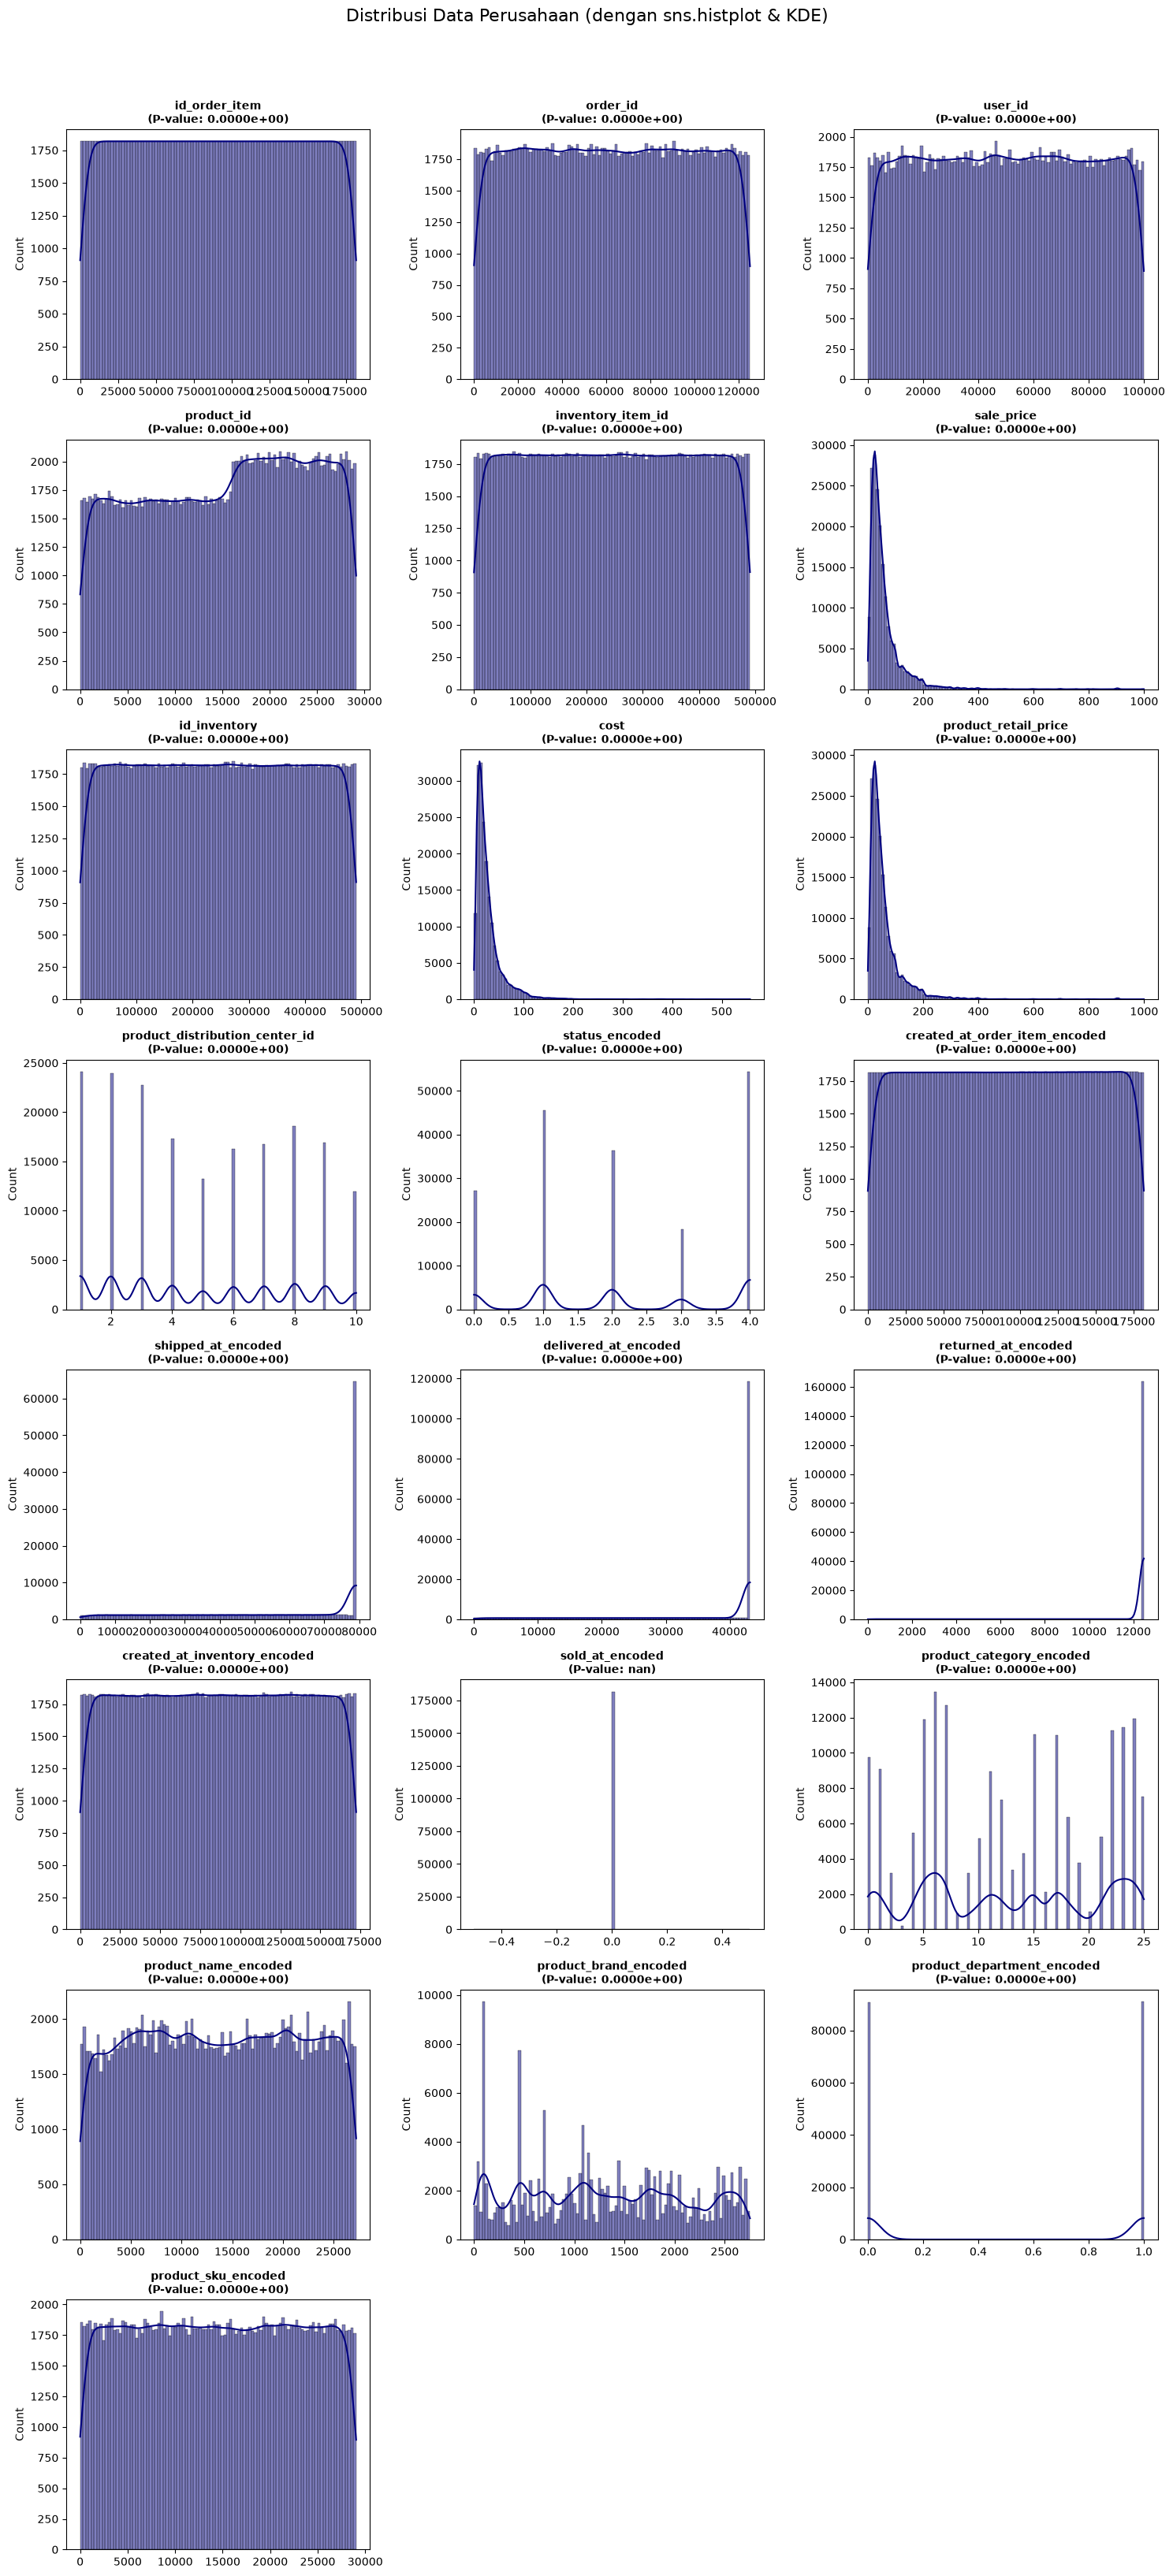

In [32]:
n_cols = 3
n_rows = int(np.ceil(len(kolom_numerik) / n_cols))

# 3. Membuat figure & axes
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()  # Meratakan array axes agar mudah di-loop

alpha = 0.05

# 4. Loop untuk plot sns.histplot dan menyisipkan P-value
for i, col in enumerate(kolom_numerik):
    # Hitung p-value (mengabaikan nilai NaN jika ada)
    data_bersih = df_copy[col].dropna()
    
    # PERBAIKAN: Cek apakah jumlah data mencukupi (minimal 8 data)
    if len(data_bersih) >= 8:
        statistic, p_value = normaltest(data_bersih)
        p_text = f"P-value: {p_value:.4e}" if p_value < 0.0001 else f"P-value: {p_value:.4f}"
        title_text = f"{col}\n({p_text})"
    else:
        title_text = f"{col}\n(Data < 8, n={len(data_bersih)})"
    
    # Menggunakan sns.histplot dengan garis KDE (Kurva Distribusi)
    # Gunakan penanganan jika data kosong sama sekali untuk menghindari error plot
    if len(data_bersih) > 0:
        sns.histplot(data_bersih, bins=100, color="navy", kde=True, ax=axes[i])
    
    # Menampilkan Nama Kolom dan P-value di judul subplot
    axes[i].set_title(title_text, fontsize=10, fontweight="bold")
    
    # Mengatur ulang label agar lebih rapi
    axes[i].set_xlabel("")
    axes[i].grid(False)

# 5. Sembunyikan subplot sisa yang tidak terpakai (jika ada kotak kosong)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribusi Data Perusahaan (dengan sns.histplot & KDE)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Heatmap

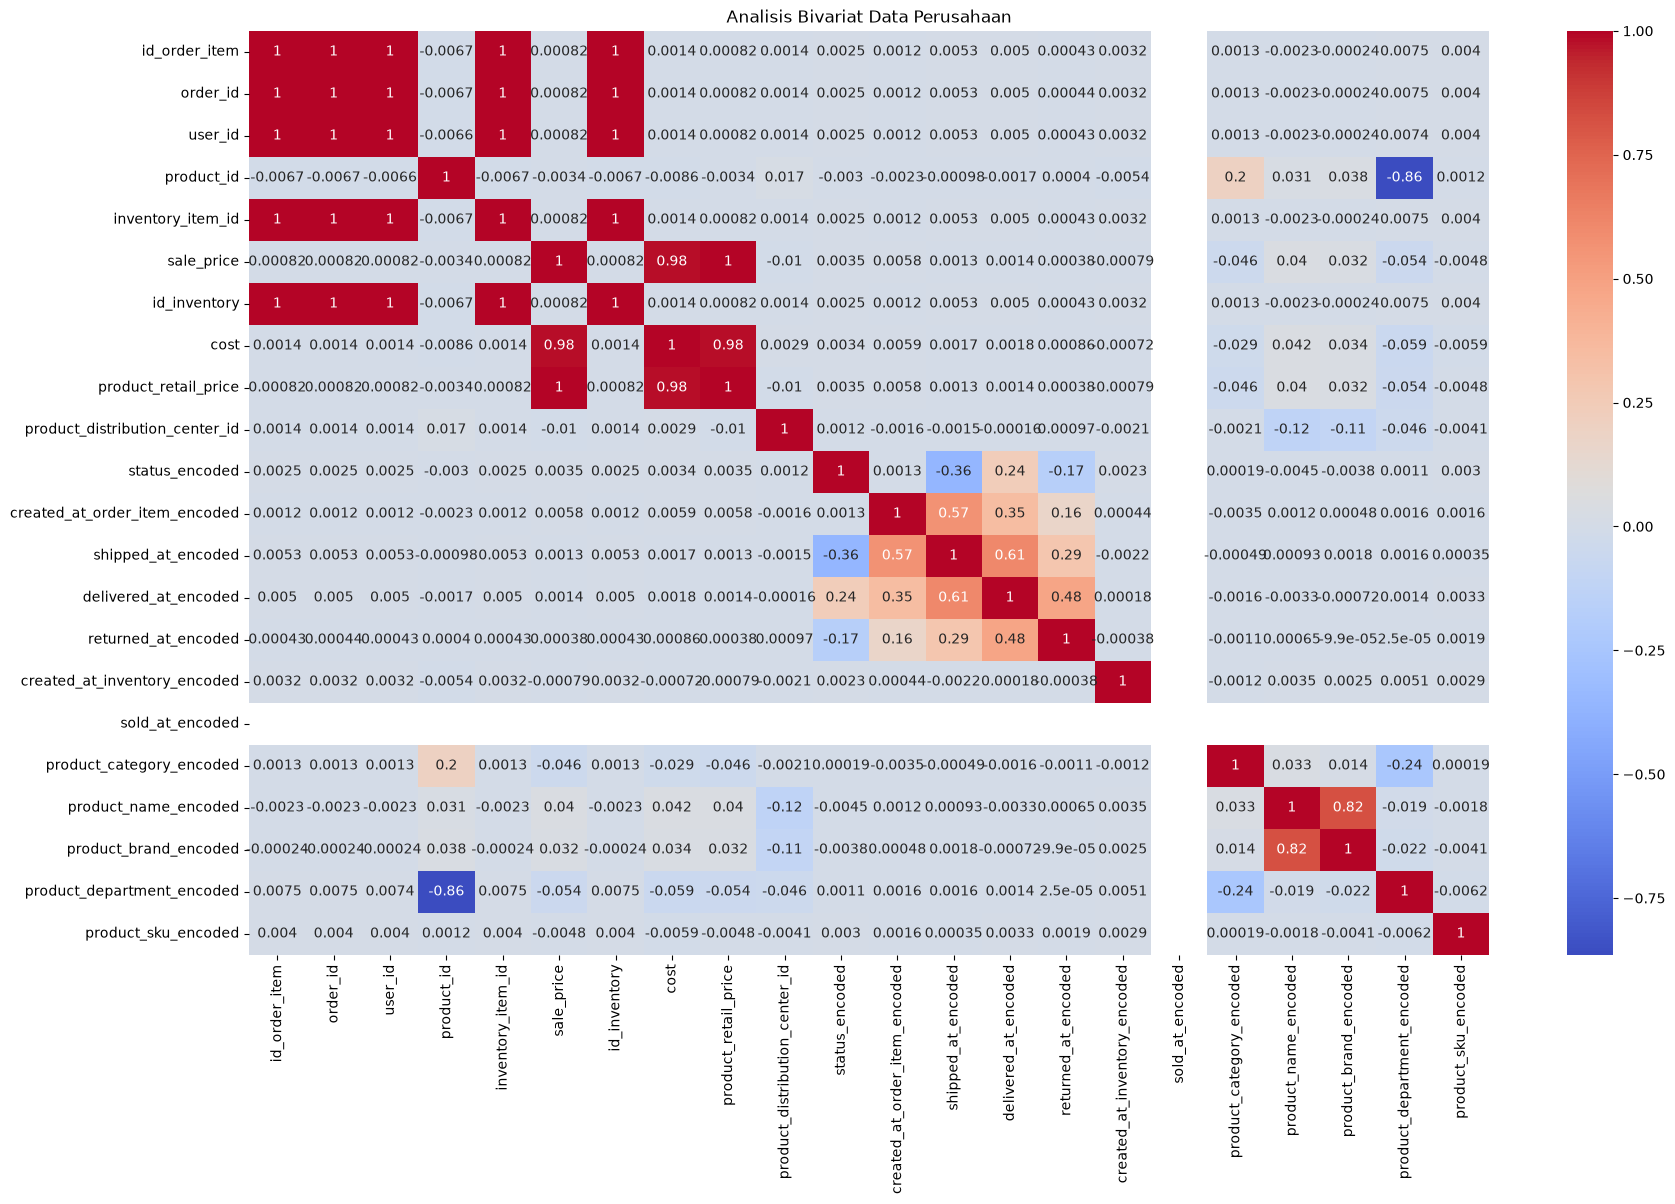

In [33]:
df_corr = numeric_df.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

### Heatmap Dengan Korelasi Tertinggi (Top 10)

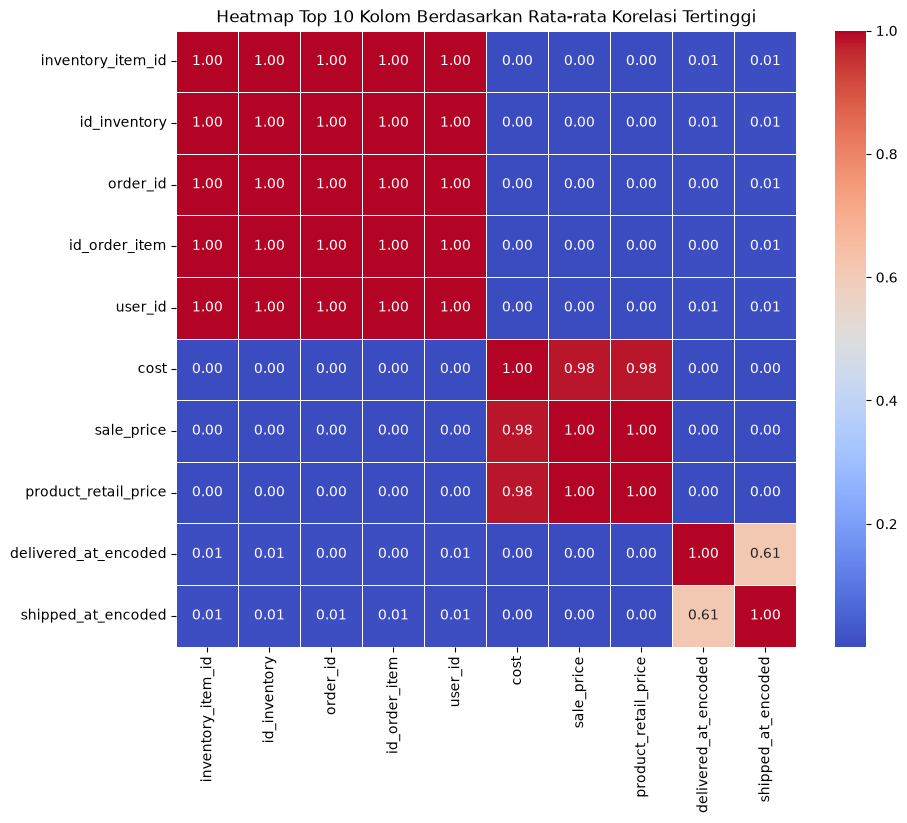

In [34]:
# Hitung matriks korelasi absolut, lalu cari 10 kolom dengan rata-rata korelasi tertinggi
top_corr_cols = numeric_df.corr().mean().nlargest(10).index
corr_top = numeric_df[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 10 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

### Heatmap Dengan Korelasi Terendah (Bottom 10)

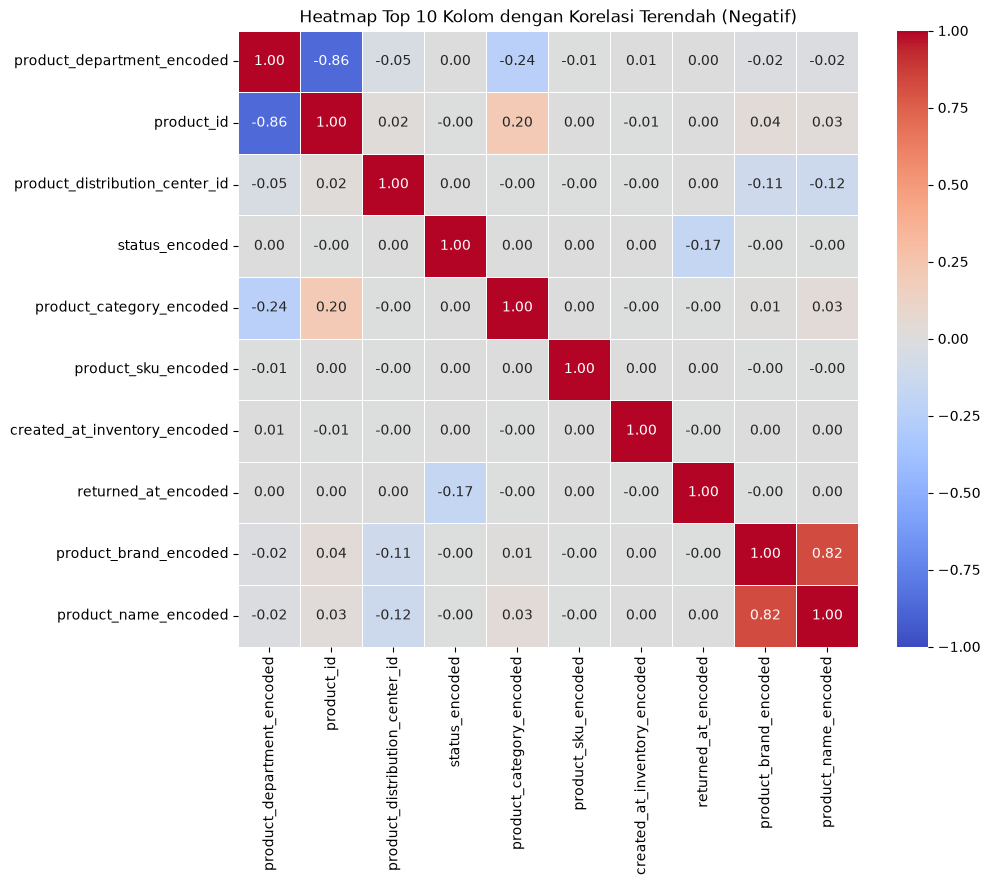

In [35]:
# Cari 10 kolom dengan rata-rata korelasi terendah (cenderung negatif)
# Gunakan .nsmallest() untuk mengambil nilai terkecil
lowest_corr_cols = numeric_df.corr().mean().nsmallest(10).index
corr_lowest = numeric_df[lowest_corr_cols].corr()

# Buat heatmap 10x10 khusus korelasi negatif/terendah
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_lowest, 
    annot=True, 
    cmap="coolwarm", 
    fmt=".2f", 
    linewidths=0.5, 
    vmin=-1,  # Mengunci batas bawah warna biru ke -1
    vmax=1    # Mengunci batas atas warna merah ke 1
)
plt.title("Heatmap Top 10 Kolom dengan Korelasi Terendah (Negatif)")
plt.show()

# Data Preparation

## Data Cleaning

### Penanganan Tipe Data

In [36]:
df_copy["id_order_item"] = df_copy["id_order_item"].astype("category")
df_copy["order_id"] = df_copy["order_id"].astype("category")
df_copy["user_id"] = df_copy["user_id"].astype("category")
df_copy["product_id"] = df_copy["product_id"].astype("category")
df_copy["inventory_item_id"] = df_copy["inventory_item_id"].astype("category")
df_copy["id_inventory"] = df_copy["id_inventory"].astype("category")
df_copy["product_distribution_center_id"] = df_copy["product_distribution_center_id"].astype("category")
df_copy["created_at_order_item"] = pd.to_datetime(df_copy["created_at_order_item"], format="ISO8601")
df_copy["shipped_at"] = pd.to_datetime(df_copy["shipped_at"], format="ISO8601")
df_copy["delivered_at"] = pd.to_datetime(df_copy["delivered_at"], format="ISO8601")
df_copy["returned_at"] = pd.to_datetime(df_copy["returned_at"], format="ISO8601")
df_copy["created_at_inventory"] = pd.to_datetime(df_copy["created_at_inventory"], format="ISO8601")
df_copy["sold_at"] = pd.to_datetime(df_copy["sold_at"], format="ISO8601")

In [37]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 181759 entries, 0 to 181758
Data columns (total 34 columns):
 #   Column                          Non-Null Count   Dtype              
---  ------                          --------------   -----              
 0   id_order_item                   181759 non-null  category           
 1   order_id                        181759 non-null  category           
 2   user_id                         181759 non-null  category           
 3   product_id                      181759 non-null  category           
 4   inventory_item_id               181759 non-null  category           
 5   status                          181759 non-null  str                
 6   created_at_order_item           181759 non-null  datetime64[us, UTC]
 7   shipped_at                      118281 non-null  datetime64[us, UTC]
 8   delivered_at                    63841 non-null   datetime64[us, UTC]
 9   returned_at                     18232 non-null   datetime64[us, UTC]
 10  sale_pr

### Penanganan Inkonsistensi

In [38]:
df_copy["product_name"] = df_copy["product_name"].str.replace(r"\s+", " ", regex=True).str.strip()
df_copy["product_name"] = df_copy["product_name"].str.capitalize()
df_copy["product_brand"] = df_copy["product_brand"].str.replace(r"\s+", " ", regex=True).str.strip()
df_copy["product_brand"] = df_copy["product_brand"].str.capitalize()

In [39]:
pd.DataFrame(df_copy["product_name"].unique()).to_excel("product_name_clean.xlsx", index=False)
pd.DataFrame(df_copy["product_brand"].unique()).to_excel("product_brand_clean.xlsx", index=False)

### Penanganan Missing Value

In [40]:
df_copy["product_brand"] = df_copy["product_brand"].fillna(df_copy["product_brand"].mode()[0])
df_copy["product_name"] = df_copy["product_name"].fillna(df_copy["product_name"].mode()[0])
df_copy = df_copy.drop(columns=["sold_at", "sold_at_encoded"])

In [41]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value
df_missing_summary = pd.DataFrame({
    "Jumlah Missing Value": df_copy_miss,
    "Persentase (%)": df_copy_miss_percentage
})
df_missing_summary = df_missing_summary.sort_values(by=("Jumlah Missing Value"), ascending=False)
display(df_missing_summary)

,Jumlah Missing Value,Persentase (%)
returned_at,163527,89.969135
delivered_at,117918,64.876017
shipped_at,63478,34.924268
id_order_item,0,0.000000
product_id,0,0.000000
inventory_item_id,0,0.000000
user_id,0,0.000000
order_id,0,0.000000
created_at_order_item,0,0.000000
status,0,0.000000


## Feature Engineering (Membuat Kolom Baru)

In [42]:
df_copy["profit"] = df_copy["sale_price"] - df_copy["cost"]

In [43]:
df_copy["terjual"] = ~df_copy["status"].isin(["Cancelled", "Returned"])

In [44]:
df_copy["margin"] = df_copy["profit"] / df_copy["sale_price"]

# EDA

## Analisis Univariat

### Distribusi cost, product_retail_price, sale_price, profit, dan margin

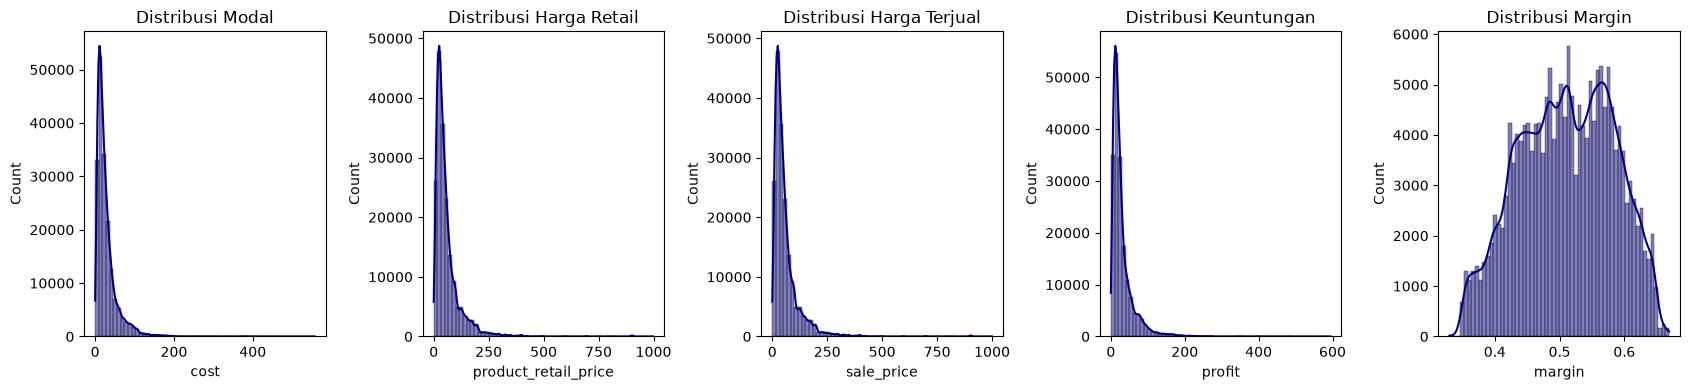

In [45]:
fig, ax = plt.subplots(1, 5, figsize=(17, 4))
sns.histplot(df_copy["cost"], bins=60, kde=True, ax=ax[0], color="navy")
ax[0].set_title("Distribusi Modal")
sns.histplot(df_copy["product_retail_price"], bins=60, kde=True, ax=ax[1], color="navy")
ax[1].set_title("Distribusi Harga Retail")
sns.histplot(df_copy["sale_price"], bins=60, kde=True, ax=ax[2], color="navy")
ax[2].set_title("Distribusi Harga Terjual")
sns.histplot(df_copy["profit"], bins=60, kde=True, ax=ax[3], color="navy")
ax[3].set_title("Distribusi Keuntungan")
sns.histplot(df_copy["margin"], bins=60, kde=True, ax=ax[4], color="navy")
ax[4].set_title("Distribusi Margin")
plt.tight_layout(); plt.show()

### Distribusi Status, Departemen Produk, dan Kategori Produk

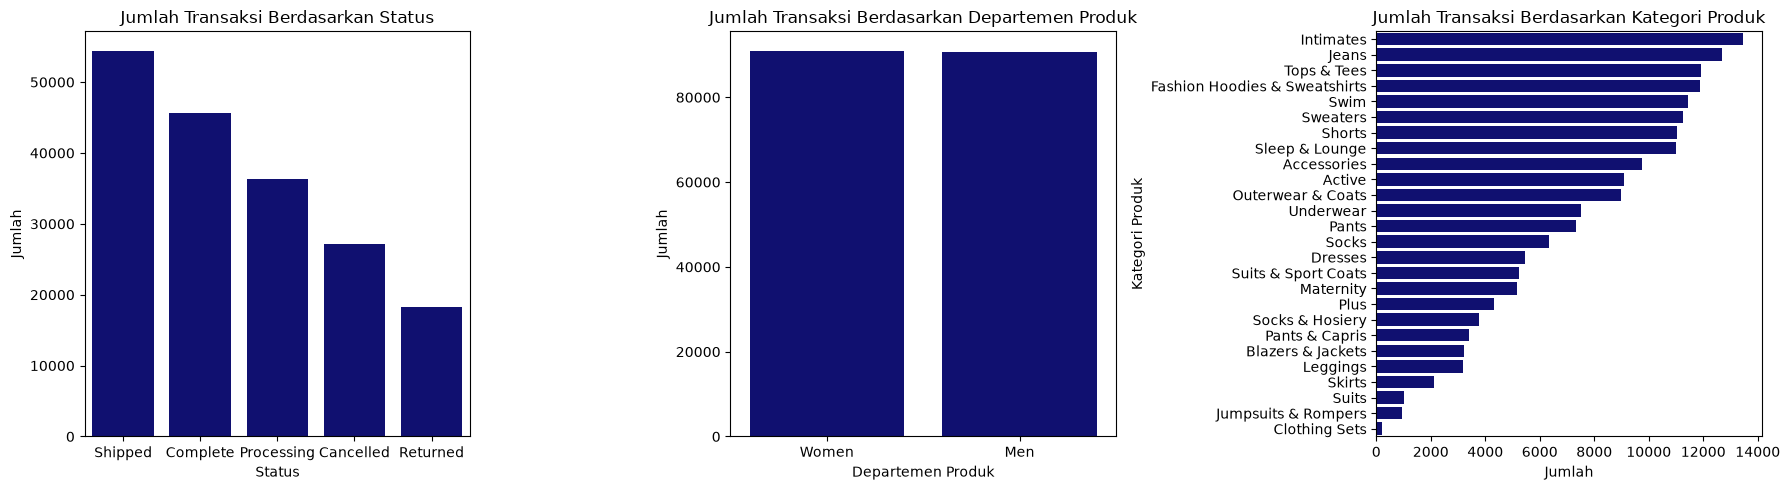

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df_copy, x="status", color="navy", ax=axes[0], order=df_copy["status"].value_counts().index)
axes[0].set_title("Jumlah Transaksi Berdasarkan Status")
axes[0].set_xlabel("Status")
axes[0].set_ylabel("Jumlah")

sns.countplot(data=df_copy, x="product_department", color="navy", ax=axes[1], order=df_copy["product_department"].value_counts().index)
axes[1].set_title("Jumlah Transaksi Berdasarkan Departemen Produk")
axes[1].set_xlabel("Departemen Produk")
axes[1].set_ylabel("Jumlah")

sns.countplot(data=df_copy, y="product_category", color="navy", ax=axes[2], order=df_copy["product_category"].value_counts().index)
axes[2].set_title("Jumlah Transaksi Berdasarkan Kategori Produk")
axes[2].set_ylabel("Kategori Produk")
axes[2].set_xlabel("Jumlah")

plt.tight_layout()
plt.show()

## Analisis Bivariat

### Uji Statistik Chi-Square Antara Pesanan Dibatalkan Dengan Departemen Produk dan Kategori Produk

In [47]:
df_copy["batal"] = df_copy["status"].isin(["Cancelled", "Returned"])

In [48]:
from scipy.stats import chi2_contingency

for kolom in ["product_department", "product_category"]:
    tabel_silang = pd.crosstab(df_copy[kolom], df_copy["batal"])
    chi2, p_value, dof, expected = chi2_contingency(tabel_silang)
    print(f"{kolom} dengan Batal -> p-value = {p_value:.4f}")
    if p_value < 0.05:
        print("Ada hubungan yang signifikan\n")
    else:
        print("Tidak ada bukti hubungan yang signifikan\n")

product_department dengan Batal -> p-value = 0.6240
Tidak ada bukti hubungan yang signifikan

product_category dengan Batal -> p-value = 0.9916
Tidak ada bukti hubungan yang signifikan



### Uji Mann-Whitney U Test Antara Pesanan Dibatalkan dengan Harga Barang

In [49]:
import numpy as np
from scipy.stats import mannwhitneyu

# Bersihkan missing values (NaN) pada kedua kolom sekaligus
df_clean = df_copy[["batal", "sale_price"]].dropna()

# Memisahkan data sale_price berdasarkan status batal (True vs False)
harga_batal = df_clean[df_clean["batal"] == True]["sale_price"]
harga_tidak_batal = df_clean[df_clean["batal"] == False]["sale_price"]

# Menjalankan uji Mann-Whitney U
stat, p_value = mannwhitneyu(
    harga_batal, harga_tidak_batal, alternative="two-sided"
)

print(f"Statistik U : {stat:.2f}")
print(f"P-value     : {p_value:.2f}")

if p_value < 0.05:
  print("Kesimpulan  : Terdapat perbedaan sale_price yang signifikan.")
else:
  print("Kesimpulan  : Tidak terdapat perbedaan sale_price yang signifikan.")

Statistik U : 3090180438.50
P-value     : 0.87
Kesimpulan  : Tidak terdapat perbedaan sale_price yang signifikan.


### Trend Keuntungan

In [50]:
'''Memfilter yang tidak dibatalkan'''
df_jual = df_copy[~df_copy["status"].isin(["Cancelled", "Returned"])]

C:\Users\AHMAD MALIK\AppData\Local\Temp\ipykernel_18180\3235075494.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_jual["order_month"] = df_jual["created_at_order_item"].dt.to_period("M")


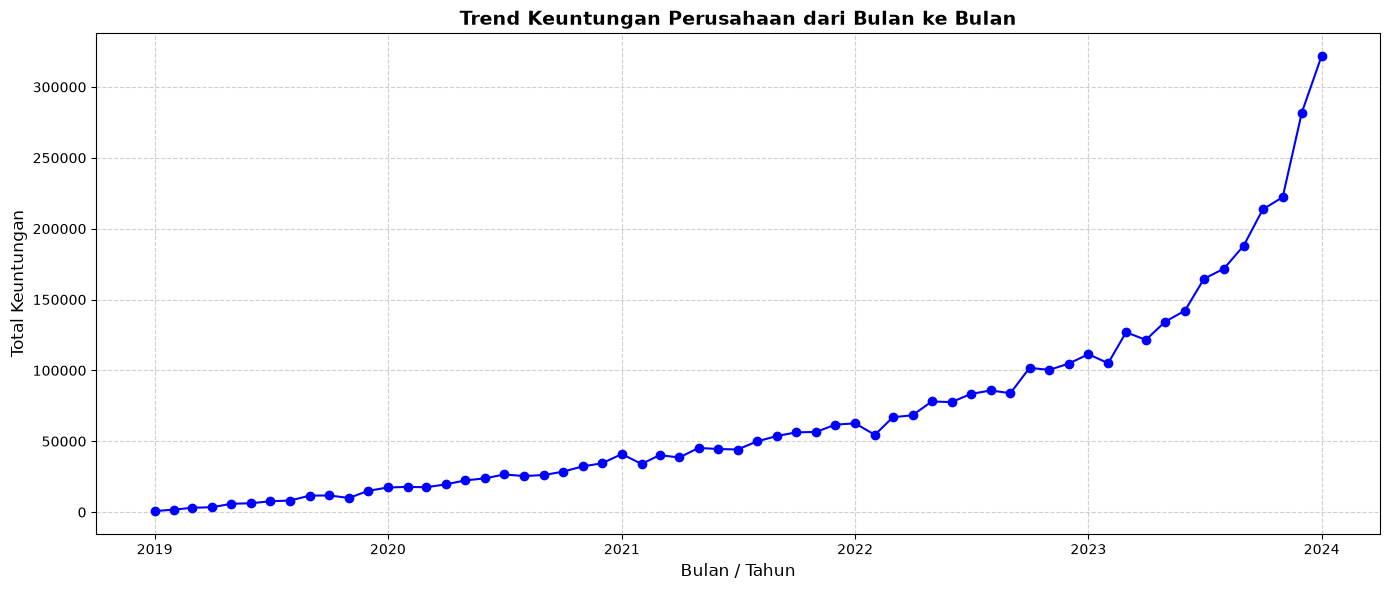

In [51]:
# 1. Buat kolom baru untuk periode bulan 
df_jual["order_month"] = df_jual["created_at_order_item"].dt.to_period("M")

# 2. Kelompokkan data (groupby) dan hitung total keuntungan per bulan
bulanan = (
    df_jual.groupby("order_month")["profit"].sum().reset_index()
)

# 3. Ubah kembali "order_month" ke timestamp agar matplotlib bisa merender garis waktu dengan benar
bulanan["order_month_ts"] = bulanan["order_month"].dt.to_timestamp()

# 4. Buat Line Plot
plt.figure(figsize=(14, 6))
plt.plot(
    bulanan["order_month_ts"],
    bulanan["profit"],
    marker="o",
    linestyle="-",
    color="b",
)

plt.title(
    "Trend Keuntungan Perusahaan dari Bulan ke Bulan",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Bulan / Tahun", fontsize=12)
plt.ylabel("Total Keuntungan", fontsize=12)

# Mengatur grid dan format agar lebih rapi
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Kategori Produk Dengan Keuntungan Tertinggi

In [52]:
produk = df_jual.groupby("product_category").agg(
    keuntungan = ("profit", "sum")
).reset_index().sort_values(by="keuntungan", ascending=False)

(array([     0., 100000., 200000., 300000., 400000., 500000., 600000.]),
 [Text(0.0, 0, '0'),
  Text(100000.0, 0, '100000'),
  Text(200000.0, 0, '200000'),
  Text(300000.0, 0, '300000'),
  Text(400000.0, 0, '400000'),
  Text(500000.0, 0, '500000'),
  Text(600000.0, 0, '600000')])

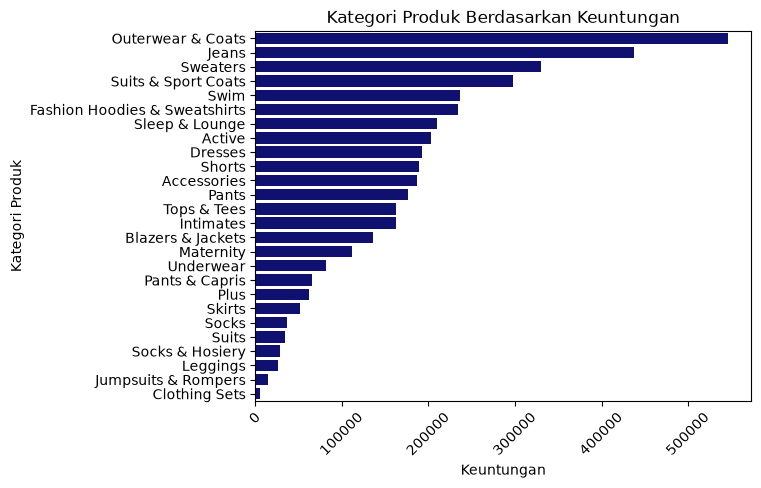

In [53]:
sns.barplot(
    data=produk,
    y="product_category",
    x="keuntungan",
    color="navy"
)
plt.title("Kategori Produk Berdasarkan Keuntungan")
plt.ylabel("Kategori Produk")
plt.xlabel("Keuntungan")
plt.xticks(rotation=45)

### Kategori Produk Dengan Margin Tertinggi

In [54]:
margin = df_jual.groupby("product_category").agg(
    margin = ("margin", "mean")
).reset_index().sort_values(by="margin", ascending=False)

(array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]),
 [Text(0.0, 0, '0.0'),
  Text(0.1, 0, '0.1'),
  Text(0.2, 0, '0.2'),
  Text(0.30000000000000004, 0, '0.3'),
  Text(0.4, 0, '0.4'),
  Text(0.5, 0, '0.5'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.7000000000000001, 0, '0.7')])

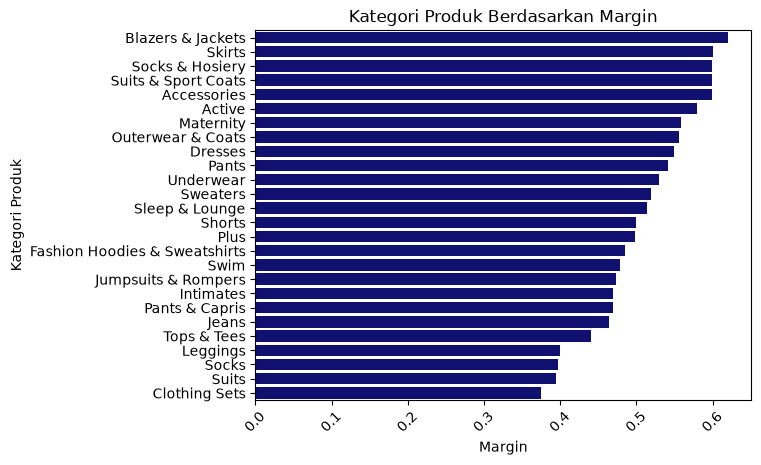

In [55]:
sns.barplot(
    data=margin,
    y="product_category",
    x="margin",
    color="navy"
)
plt.title("Kategori Produk Berdasarkan Margin")
plt.ylabel("Kategori Produk")
plt.xlabel("Margin")
plt.xticks(rotation=45)

### Departemen Produk Berdasarkan Keuntungan

In [56]:
departemen_prof = df_jual.groupby("product_department").agg(
    Keuntungan = ("profit", "sum")
).reset_index().sort_values(by="Keuntungan", ascending=False)

([0, 1], [Text(0, 0, 'Men'), Text(1, 0, 'Women')])

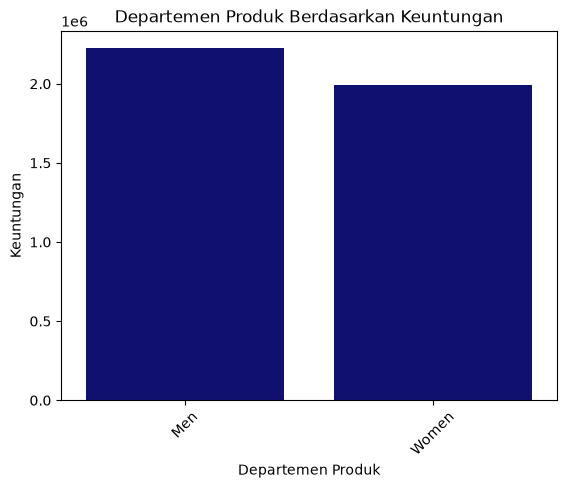

In [57]:
sns.barplot(
    data=departemen_prof,
    y="Keuntungan",
    x="product_department",
    color="navy"
)
plt.title("Departemen Produk Berdasarkan Keuntungan")
plt.xlabel("Departemen Produk")
plt.ylabel("Keuntungan")
plt.xticks(rotation=45)

### Departemen Produk Berdasarkan Margin

In [58]:
departemen_margin = df_jual.groupby("product_department").agg(
    margin = ("margin", "mean")
).reset_index().sort_values(by="margin", ascending=False)

([0, 1], [Text(0, 0, 'Women'), Text(1, 0, 'Men')])

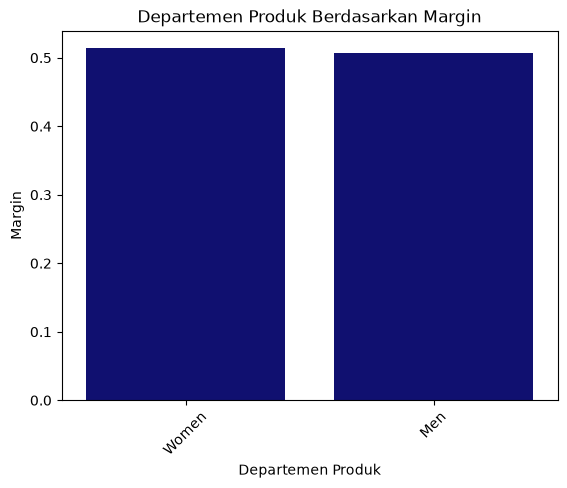

In [59]:
sns.barplot(
    data=departemen_margin,
    y="margin",
    x="product_department",
    color="navy"
)
plt.title("Departemen Produk Berdasarkan Margin")
plt.xlabel("Departemen Produk")
plt.ylabel("Margin")
plt.xticks(rotation=45)

## Analisis Multivariat

### Keuntungan Berdasarkan Kategori Produk dan Departemen Produk

In [60]:
multi = df_jual.pivot_table(index="product_category", columns="product_department", values="profit", aggfunc="sum")

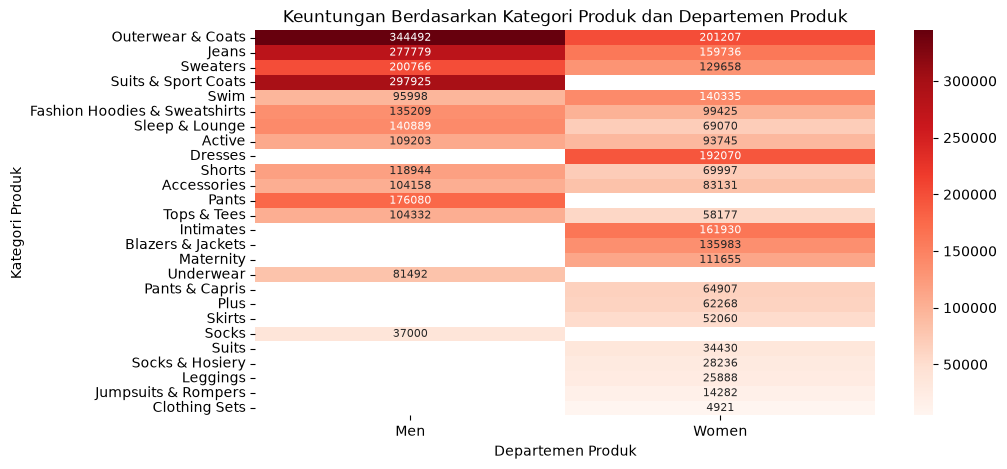

In [61]:
# Hitung total per baris dan urutkan indeks baris
sorted_rows = multi.sum(axis=1).sort_values(ascending=False).index

# Hitung total per kolom dan urutkan indeks kolom
sorted_cols = multi.sum(axis=0).sort_values(ascending=False).index

# Reindex dataframe multi berdasarkan urutan baru
multi_sorted = multi.loc[sorted_rows, sorted_cols]

plt.figure(figsize=(10, 5))
sns.heatmap(multi_sorted, annot=True, fmt=".0f", cmap="Reds", annot_kws={"size": 8})
plt.title("Keuntungan Berdasarkan Kategori Produk dan Departemen Produk")
plt.xlabel("Departemen Produk")
plt.ylabel("Kategori Produk")
plt.show()

### Margin Berdasarkan Kategori Produk dan Departemen Produk

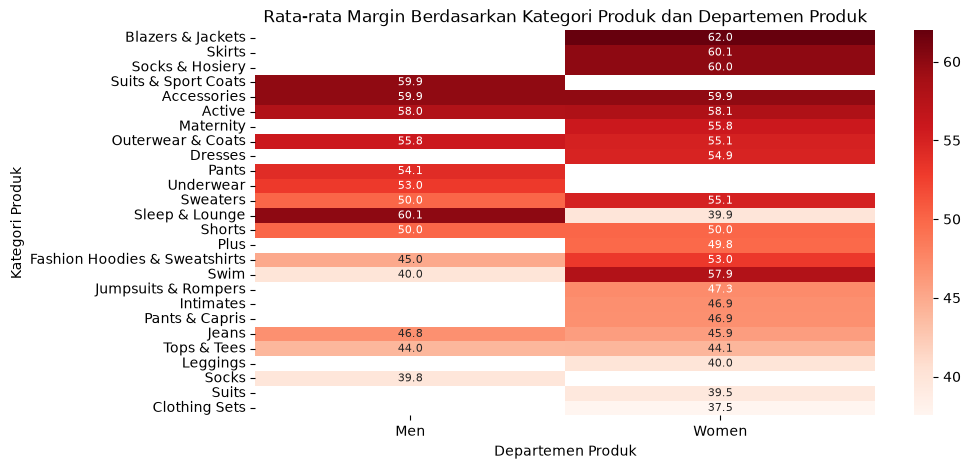

In [62]:
# 1. Buat pivot table dengan margin dan aggfunc="mean" (dikalikan 100 jika ingin bentuk persentase)
multi = df_jual.pivot_table(
    index="product_category", 
    columns="product_department", 
    values="margin", 
    aggfunc="mean"
) * 100

# 2. Urutkan baris dan kolom berdasarkan nilai rata-rata (mean) terbesar ke terkecil
sorted_rows = multi.mean(axis=1).sort_values(ascending=False).index
sorted_cols = multi.mean(axis=0).sort_values(ascending=False).index

# 3. Reindex dataframe sesuai urutan baru
multi_sorted = multi.loc[sorted_rows, sorted_cols]

# 4. Buat heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(multi_sorted, annot=True, fmt=".1f", cmap="Reds", annot_kws={"size": 8})
plt.title("Rata-rata Margin Berdasarkan Kategori Produk dan Departemen Produk")
plt.xlabel("Departemen Produk")
plt.ylabel("Kategori Produk")
plt.show()

# Ekstrak Data

In [63]:
df_clean = df_copy.copy()

In [64]:
df_clean.drop(columns=[
    "status_encoded",
    "created_at_order_item_encoded",
    "shipped_at_encoded",
    "delivered_at_encoded",
    "returned_at_encoded",
    "created_at_inventory_encoded",
    "product_category_encoded",
    "product_name_encoded",
    "product_brand_encoded",
    "product_department_encoded",
    "product_sku_encoded"
], inplace=True)

In [65]:
df_clean.to_csv("Data_Ecommerce_clean.csv", index=False, sep=";", encoding="utf-8")